In [1]:
# importing necessary libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from tensorflow.keras.layers import Dense, Input, Activation
from tensorflow.keras.models import Model
from tensorflow.keras import metrics
from tensorflow.keras.losses import MeanSquaredError 

2026-09-16 19:01:44.436842: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# Polynomial function
def polynomial(x):
    return 5 * x**3 - 10 * x**2 - 20 * x + 10

In [3]:
# Generate data
x = np.linspace(-20, 20, 5000).reshape(-1,1)
y = polynomial(x) 

In [4]:
# Normalize to [-1, 1]
x_scaler = MinMaxScaler(feature_range=(-1,1))
y_scaler = MinMaxScaler(feature_range=(-1,1))

x_norm = x_scaler.fit_transform(x)
y_norm = y_scaler.fit_transform(y)

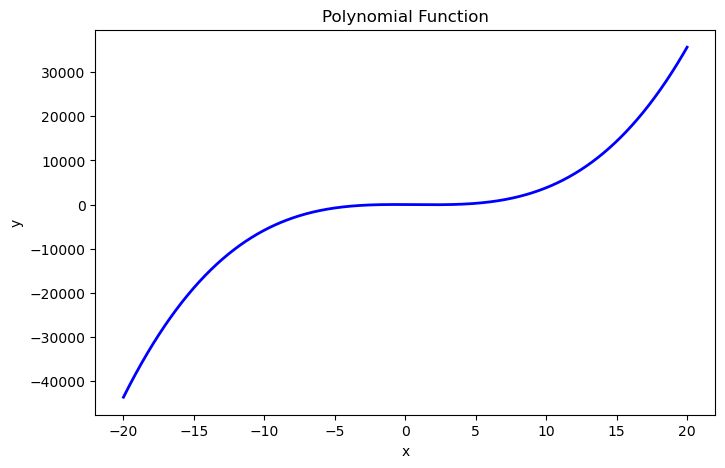

In [5]:
# simple plot this polinomial value
plt.figure(figsize=(8,5))
plt.plot(x, y, color='blue', linewidth=2)
plt.title("Polynomial Function")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

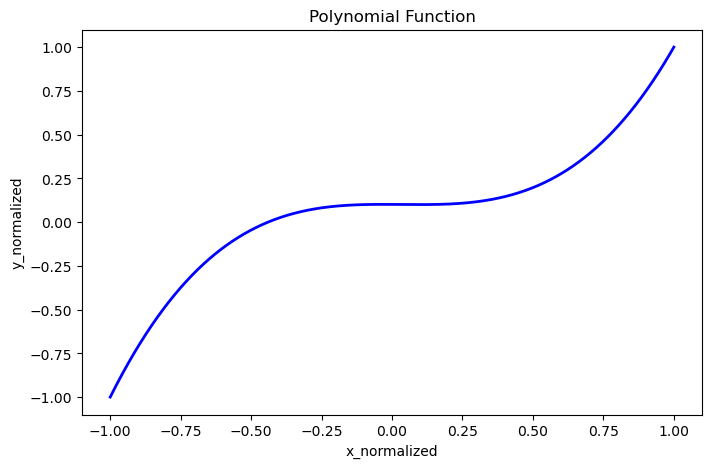

In [6]:
plt.figure(figsize=(8,5))
plt.plot(x_norm, y_norm, color='blue', linewidth=2)
plt.title("Polynomial Function")
plt.xlabel("x_normalized")
plt.ylabel("y_normalized")
plt.show()

In [7]:
# splitting the data into training and testing sets
X_train, X_temp, y_train, y_temp = train_test_split(
    x_norm,
    y_norm,
    test_size=0.20,
    random_state=42
)

In [8]:
X_train.shape

(4000, 1)

In [9]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42
)

In [10]:
# Build model
model = tf.keras.Sequential([
    Input(shape=(1,)), 
    Dense(32, activation='relu'),
    Dense(64, activation='relu'),
    Dense(128, activation='relu'),
    Dense(1)
])


In [11]:
model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

In [12]:
# Train
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    verbose=1
)

Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0162 - mae: 0.0876 - val_loss: 0.0027 - val_mae: 0.0336
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 8.8351e-04 - mae: 0.0187 - val_loss: 2.7242e-04 - val_mae: 0.0109
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.5685e-04 - mae: 0.0080 - val_loss: 6.8637e-05 - val_mae: 0.0045
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 7.6433e-05 - mae: 0.0057 - val_loss: 4.3562e-05 - val_mae: 0.0047
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3.1269e-05 - mae: 0.0036 - val_loss: 1.6443e-05 - val_mae: 0.0024
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2.1838e-05 - mae: 0.0031 - val_loss: 1.5829e-05 - val_mae: 0.0026
Epoch 7/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.2960e-05 - mae: 0.0025 - val_loss: 9.2366e-06 - val_mae: 0.0018
Epoch 8/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.3305e-05 - mae: 0.0025 - val_loss: 1.0687e-05 - val_mae:

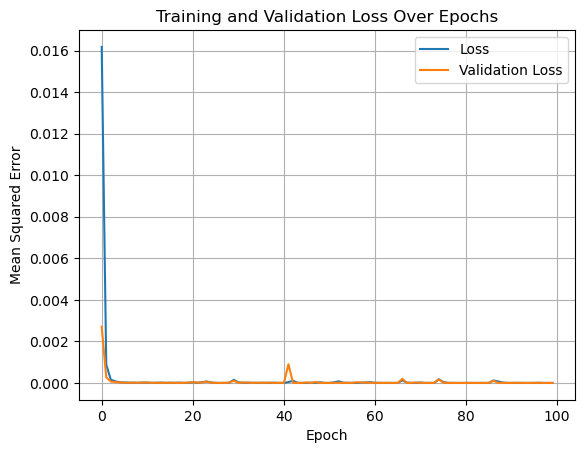

In [13]:
plt.plot(history.history['loss'], label='Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.title('Training and Validation Loss Over Epochs')
plt.grid(True)
plt.show()

In [14]:
loss, mae = model.evaluate(X_test, y_test, verbose=0)

print("\nTest MSE :", loss)
print("Test MAE :", mae)


Test MSE : 1.0897986157942796e-06
Test MAE : 0.0008128548506647348


In [15]:
from sklearn.metrics import r2_score

y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
print(f'R2 Score on Test Set: {r2:.6f}')

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
R2 Score on Test Set: 0.999993


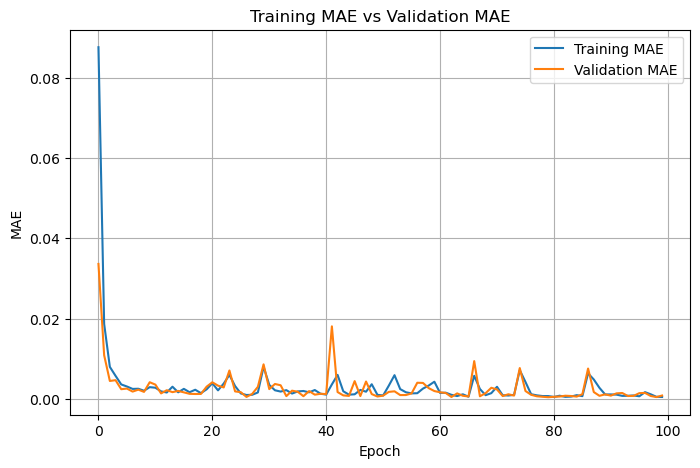

In [16]:
# Plot Training vs Validation MAE

plt.figure(figsize=(8,5))
plt.plot(history.history['mae'], label='Training MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')
plt.title("Training MAE vs Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.legend()
plt.grid(True)
plt.show()

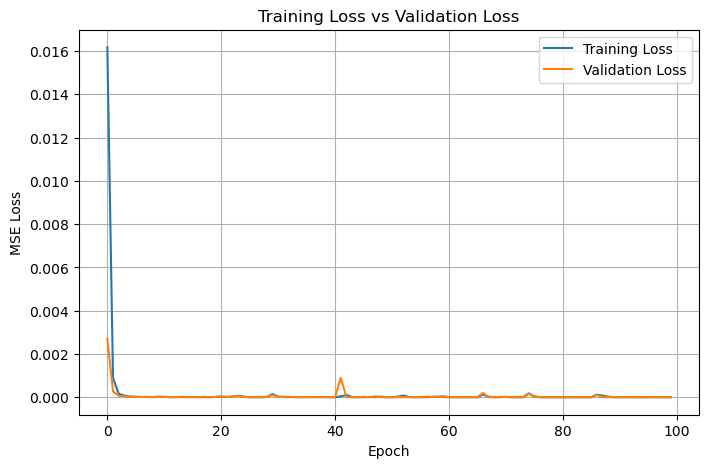

In [17]:
# Plot Training vs Validation Loss

plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("Training Loss vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

In [18]:
x_new = np.array([[5]])
x_new_norm = x_scaler.transform(x_new)

prediction_norm = model.predict(x_new_norm)

prediction = y_scaler.inverse_transform(prediction_norm)

actual = 5*(5**3)-10*(5**2)-20*5+10


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


In [19]:
print("\nInput x =", x_new[0][0])
print("Predicted y =", prediction[0][0])
print("Actual y =", actual)


Input x = 5
Predicted y = 273.15173
Actual y = 285


Test prediction accuracy: 99.70%
Test MAE: 32.1892

True y versus predicted y:
True:  3393.0808 | Predicted:  3377.0684
True: -13473.7641 | Predicted: -13513.4980
True:   -22.2483 | Predicted:   -32.2098
True: -8957.9642 | Predicted: -8988.0645
True:   456.1161 | Predicted:   459.2985
True: 10482.3738 | Predicted: 10448.7764
True: -2983.5841 | Predicted: -2999.5508
True: -9902.5423 | Predicted: -9935.4414
True:   -29.9996 | Predicted:   -57.9134
True: 16137.5913 | Predicted: 16109.3955
True: -2914.4029 | Predicted: -2926.2039
True: -16406.1689 | Predicted: -16458.7578
True: -8141.8787 | Predicted: -8179.0693
True: -5078.1302 | Predicted: -5097.6914
True: -36870.6235 | Predicted: -36964.3164
True:  1682.1828 | Predicted:  1669.1865
True: 20743.9834 | Predicted: 20690.3164
True:   986.6448 | Predicted:   990.9211
True: -5653.2860 | Predicted: -5674.2886
True:  2001.9051 | Predicted:  1996.7551


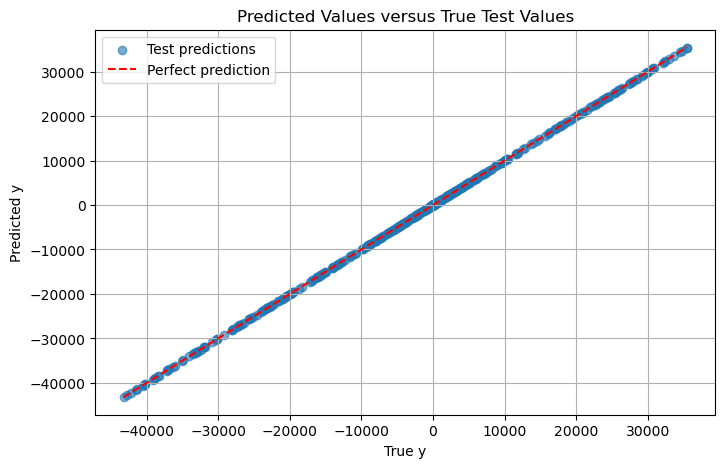

In [20]:
# Predict on the test data and compare with the true values
y_test_pred_norm = model.predict(X_test, verbose=0)
y_test_pred = y_scaler.inverse_transform(y_test_pred_norm)
y_test_true = y_scaler.inverse_transform(y_test)

absolute_error = np.abs(y_test_true - y_test_pred)
mae_test = np.mean(absolute_error)
prediction_accuracy = (1 - mae_test / np.mean(np.abs(y_test_true))) * 100

print(f"Test prediction accuracy: {prediction_accuracy:.2f}%")
print(f"Test MAE: {mae_test:.4f}")
print("\nTrue y versus predicted y:")
for true_value, predicted_value in zip(y_test_true[:20].ravel(), y_test_pred[:20].ravel()):
    print(f"True: {true_value:10.4f} | Predicted: {predicted_value:10.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(y_test_true, y_test_pred, alpha=0.6, label="Test predictions")
plot_limits = [min(y_test_true.min(), y_test_pred.min()), max(y_test_true.max(), y_test_pred.max())]
plt.plot(plot_limits, plot_limits, "r--", label="Perfect prediction")
plt.title("Predicted Values versus True Test Values")
plt.xlabel("True y")
plt.ylabel("Predicted y")
plt.legend()
plt.grid(True)
plt.show()